## 1. Install the required packages

In [4]:
%pip install kagglehub librosa matplotlib ipython opencv-python mediapipe tqdm numpy ffmpeg imageio[ffmpeg] joblib

Note: you may need to restart the kernel to use updated packages.


## 2. Download the CREMA-D dataset from Kaggle

In [5]:
from pathlib import Path

import kagglehub

# Download latest version
path = kagglehub.dataset_download("orvile/crema-d-emotional-multimodal-dataset")
path = Path(path) / "content" / "CREMA-D"

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Jere\.cache\kagglehub\datasets\orvile\crema-d-emotional-multimodal-dataset\versions\1\content\CREMA-D


## 3. Extract the landmarks from the videos using MediaPipe and save them as .npy files to the `Landmarks` folder.

In [6]:
from joblib import Parallel, delayed
from tqdm.auto import tqdm
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks.python import BaseOptions, vision

INPUT_VIDEO_DIR = path / "VideoFlash"
OUTPUT_DATA_DIR = Path("Landmarks")
OUTPUT_DATA_DIR.mkdir(parents=True, exist_ok=True)

def process_video_worker(video_path):
    npy_path = OUTPUT_DATA_DIR / video_path.with_suffix(".npy").name
    if npy_path.exists():
        return  # Skip already processed files

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        print(f"Warning: Could not open video {video_path.name}")
        return

    # Initialize MediaPipe locally inside each worker process
    base_options = BaseOptions(model_asset_path="face_landmarker.task")
    options = vision.FaceLandmarkerOptions(
        base_options=base_options,
        running_mode=vision.RunningMode.VIDEO,
        output_face_blendshapes=False,
        output_facial_transformation_matrixes=False,
        num_faces=1,
    )
    detector = vision.FaceLandmarker.create_from_options(options)

    video_sequence = []
    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps <= 0 or np.isnan(fps):
        fps = 30.0

    frame_idx = 0
    timestamp_offset = 0

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret or frame is None:
            break

        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_frame)
        current_ts = timestamp_offset + int((frame_idx / fps) * 1000)
        
        results = detector.detect_for_video(mp_image, current_ts)

        if results.face_landmarks:
            frame_landmarks = [[lm.x, lm.y, lm.z] for lm in results.face_landmarks[0]]
            video_sequence.append(frame_landmarks)
        else:
            video_sequence.append(np.zeros((478, 3)))

        frame_idx += 1

    cap.release()

    if video_sequence:
        np_sequence = np.array(video_sequence, dtype=np.float32)
        np.save(npy_path, np_sequence)

# Run across all CPU cores using joblib
video_files = list(INPUT_VIDEO_DIR.glob("*.flv"))
print(f"Extracting landmarks from {len(video_files)} videos using joblib multiprocessing...")

# n_jobs=-1 utilizes all available CPU cores safely on Windows
Parallel(n_jobs=-1)(
    delayed(process_video_worker)(video) 
    for video in tqdm(video_files)
)

print("Landmark extraction complete!")

Extracting landmarks from 7442 videos using joblib multiprocessing...


100%|██████████| 7442/7442 [10:37<00:00, 11.67it/s]


Landmark extraction complete!


## 4. Visualize the results on a random sample

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (480, 360) to (480, 368) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Loading Multi-Modal Data for Actor: 1039 | Emotion: HAP
Video loaded. Resolution: 480x360, FPS: 29.97
Successfully saved 91 frames to out.mp4


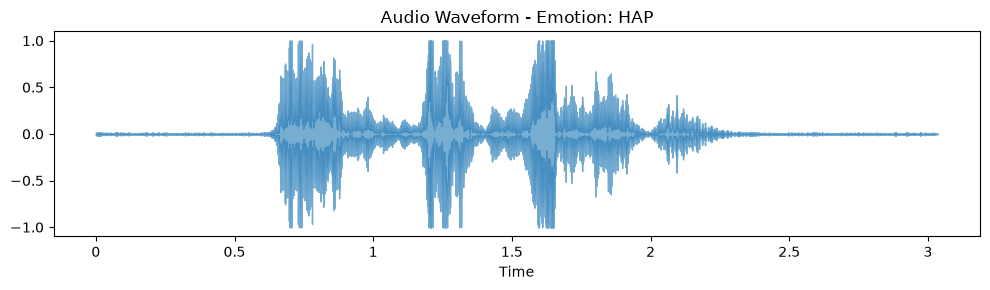

In [8]:
import os
import random
from pathlib import Path
import cv2
import numpy as np
import imageio.v3 as iio

import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, Video, display

AUDIO_PATH = path / "AudioWAV"
VIDEO_PATH = path / "VideoFlash"
LANDMARK_PATH = Path("Landmarks")

data = []
for file in list(LANDMARK_PATH.glob("*.npy")):
    parts = file.stem.split("_")
    data.append(
        {
            "ActorID": parts[0],
            "Sentence": parts[1],
            "Emotion": parts[2],
            "Intensity": parts[3],
            "AudioPath": AUDIO_PATH / f"{file.stem}.wav",
            "VideoPath": VIDEO_PATH / f"{file.stem}.flv",
            "LandmarkPath": file,
        }
    )

sample = random.choice(data)
print(
    f"Loading Multi-Modal Data for Actor: {sample['ActorID']} | Emotion: {sample['Emotion']}"
)
input_flv = str(sample["VideoPath"])


# Load video with OpenCV
cap = cv2.VideoCapture(input_flv)

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

# Fallback for invalid FPS reading
if fps <= 0 or np.isnan(fps):
    fps = 30.0

print(f"Video loaded. Resolution: {width}x{height}, FPS: {fps:.2f}")

landmarks_seq = np.load(sample["LandmarkPath"])

frames = []
for landmarks in landmarks_seq:
    ret, frame = cap.read()
    if not ret or frame is None:
        break
    
    # Draw landmarks
    for x, y, _ in landmarks:
        cv2.circle(frame, (int(x * width), int(y * height)), 1, (0, 255, 0), -1)
    
    # OpenCV uses BGR; convert to RGB for imageio
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append(frame_rgb)

cap.release()

if len(frames) == 0:
    raise RuntimeError(f"Could not read frames from video: {input_flv}")

out_mp4 = "out.mp4"

# Write directly to H.264 MP4 using imageio's internal bindings
iio.imwrite(
    out_mp4,
    frames,
    fps=fps if fps > 0 else 30.0,
    codec="libx264",
    pixelformat="yuv420p"
)

print(f"Successfully saved {len(frames)} frames to {out_mp4}")

display(Video(out_mp4, embed=True))

y, sr = librosa.load(sample["AudioPath"], sr=None)
display(Audio(data=y, rate=sr))
plt.figure(figsize=(10, 3))
librosa.display.waveshow(y, sr=sr, alpha=0.6)
plt.title(f"Audio Waveform - Emotion: {sample['Emotion']}")
plt.tight_layout()
plt.show()